# Assignment 03: Topic modeling using descriptions

**Overall purpose:** Answer the five crime-data questions on slide 11 using reproducible topic modeling and evidence-based report analysis. Your section must connect to the shared final report table and the main workstation.

## Shared rules: read before writing code

1. **Claim one assignment.** Add your name and reviewer below, then tell the group. These six notebooks are roles, not six tasks for each person.
2. **Use the shared files.** The original Parquet and shared/reports_base.parquet are read-only inputs. The base adds stable report_id values but does not clean or classify anything.
3. **Keep report_id.** Never recreate IDs after filtering, sorting or resetting an index. Join results using report_id with merge validation. URL is not a unique ID: some URLs repeat.
4. **Use one prepared version.** Member 1 must publish outputs/member_01/reports_prepared.parquet before final modeling. Preserve all source rows and mark exclusions. Everyone records that file's checksum in run_metadata.json. Prototype results on the base are exploratory and must be rerun on the agreed prepared file.
5. **Preserve alignment.** Build each text list and embedding matrix from the same filtered DataFrame in the same order. Never filter/sort text and embeddings separately.
6. **Separate analysis from evidence.** Write short code cells, show readable tables/plots, and explain actual outputs. Do not invent findings, silently fill missing districts, or treat a colored cluster plot as proof of meaningful crime types.
7. **Export to your own folder.** outputs/member_XX holds submissions; figures/member_XX holds readable figures. templates/member_XX contains empty examples and is never a finished submission.
8. **Finish with a peer review.** Everyone contributes their section, interpretation and sample reading. Member 6 coordinates validation; they do not write the entire group project.

**Your name:** ______  
**Peer reviewer:** ______  
**Status:** Not started / In progress / Ready for review / Accepted  
**Prepared input version/checksum:** ______


## Setup and input check

Keep this notebook inside team_notebooks, or beside the shared folder. Copy the project folder when sharing it; the notebook alone does not contain the dataset.

In [1]:
from pathlib import Path
import pandas as pd
import json

In [2]:
project_folder = Path.cwd()
if not (project_folder / "shared").exists():
    project_folder = project_folder.parent

assert (project_folder / "shared/source_manifest.json").exists(), "Open the notebook from the shared project folder."

In [3]:
output_folder = project_folder / "outputs/member_03"
figure_folder = project_folder / "figures/member_03"
output_folder.mkdir(parents=True, exist_ok=True)
figure_folder.mkdir(parents=True, exist_ok=True)

In [4]:
text_columns = ["report_id", "date_posted", "title_en", "description_en", "district", "url"]
reports_base = pd.read_parquet(project_folder / "shared/reports_base.parquet", columns=text_columns)
assert reports_base["report_id"].is_unique
print("Base reports:", len(reports_base))
reports_base[["report_id", "date_posted", "title_en", "district"]].head(3)

Base reports: 5126


,report_id,date_posted,title_en,district
0,BR000000,2026-09-03,Police release wanted photo after shooting in ...,Woltmershausen
1,BR000001,2026-09-03,Burglary in Bar - Police Catch Perpetrators,Ostertor
2,BR000002,2026-09-02,Paint vandalism at high school,Horn


In [5]:
prepared_path = project_folder / "outputs/member_01/reports_prepared.parquet"
if prepared_path.exists():
    prepared_columns = text_columns + ["district_clean", "include_in_analysis", "exclusion_reason"]
    reports = pd.read_parquet(prepared_path, columns=prepared_columns)
    print("Prepared input available. Check its version before modeling.")
else:
    print("Preparation pending: final modeling and group analysis must wait for Member 1.")

Preparation pending: final modeling and group analysis must wait for Member 1.


### Packages

Use the agreed group environment. From the project folder, the setup command is `python -m pip install -r requirements.txt`. Do this only when preparing the modeling environment. The skeleton uses pandas/pyarrow; BERTopic, UMAP and HDBSCAN are not installed in the environment used to check these starter notebooks. No algorithm has been run yet.

## Things to note throughout the project

- Count reports, not confirmed incidents or individual victims. One report can discuss several events or offenses. Treat the unit consistently.
- date_posted is a publication date. The first/last years and boundary months are partial; the source's collection coverage is not established by its date range alone.
- District labels include literal None and potentially different geographic levels. Unknown district reports still matter for citywide totals; district rankings need a consistent reviewed geography.
- Categories such as Theft, Traffic-related, Assault, Burglary, Fraud and Drug-related are candidate names, not predetermined model results. Include an Unknown/Unclear option and a documented non-crime/report-type category where needed.
- A topic is a group of similar reports, not automatically a legal crime category. Several topics can map to one category; mixed topics may need a per-report review.
- Use one primary category per report for the main count tables. If the group later adopts multiple labels, document that totals can exceed the report count and rebuild all comparisons consistently.
- The source includes descriptions of harmful events. Keep relevant evidence brief in outputs, avoid unnecessary identifying details, and use report IDs/source URLs for traceability.
- No API calls, paid services, extra scraping or AI-generated embeddings are needed to start. Optional AI-assisted elderly detection needs a separate agreed method and human verification.


## Purpose and dependencies

You build a topic model using **description_en**. This experiment is central to the group project. Discover groups of words/reports, explain them using real examples, and help turn them into useful crime categories.

**Final input:** Member 1's frozen prepared table. **Method:** TF-IDF + non-negative matrix factorization (NMF). **Model ID:** nmf_descriptions. **Comparison partner:** Member 2 titles. Match their evaluation report IDs and agreed parameter candidates; do not choose a winner in advance.

Your results support Question 1 and supply labels for Questions 2–5. You submit a candidate model; Member 6 coordinates the group's final model/category decision.

### 1. Define the documents and eligible reports

Use only description_en as the model text. Keep the original text and report IDs. Check missing/blank input and shared inclusion flags. Use one common eligible report set for the formal title/description comparison; document additional coverage separately. Never discard missing inputs without recording their assignment_status.

In [6]:

# Check the total number of police reports
print("Total police reports:", len(reports_base))

# Check for missing or empty descriptions
descriptions = reports_base["description_en"].fillna("").astype(str).str.strip()

missing_descriptions = (descriptions == "").sum()
valid_descriptions = (descriptions != "").sum()

print("Reports with descriptions:", valid_descriptions)
print("Reports without descriptions:", missing_descriptions)

Total police reports: 5126
Reports with descriptions: 5126
Reports without descriptions: 0


### Interpretation: Document availability and eligibility

**What did I observe?**

The dataset contains 5,126 police reports, and all 5,126 reports have non-empty English descriptions. No reports were identified with missing or blank descriptions.

**Why does this matter?**

This is a positive starting point for topic modelling because every report contains text that can potentially be analysed to identify common crime-related themes. No reports need to be excluded solely because their descriptions are missing or empty.

**What remains uncertain?**

Although all reports contain descriptions, their quality, length and relevance have not yet been assessed. The final number of eligible reports also depends on the shared data preparation and inclusion criteria established by Member 1.

**Explain your output:** What did you observe? Why does it matter? What remains uncertain?

### 2. Turn text into a word matrix

Use TfidfVectorizer. Start with English stopwords and one-/two-word phrases; inspect frequent generic police boilerplate and place names. Remove only documented terms that obscure crime meaning. Retain meaningful phrases such as bike theft and traffic accident. Explain TF-IDF simply: common generic words get less weight; informative words help separate reports.

In [7]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90
)

# Convert descriptions into a word matrix
tfidf_matrix = vectorizer.fit_transform(descriptions)

# Display the results
print("Number of police reports:", tfidf_matrix.shape[0])
print("Number of words and phrases:", tfidf_matrix.shape[1])


Number of police reports: 5126
Number of words and phrases: 31905


In [8]:

import pandas as pd
import numpy as np

# Get all words and phrases
feature_names = vectorizer.get_feature_names_out()

# Count how many reports contain each term
term_counts = np.asarray(
    (tfidf_matrix > 0).sum(axis=0)
).ravel()

# Create a table of frequent terms
frequent_terms = pd.DataFrame({
    "Word or Phrase": feature_names,
    "Number of Reports": term_counts
})

# Show the 20 most frequent terms
frequent_terms.sort_values(
    "Number of Reports",
    ascending=False
).head(20)


,Word or Phrase,Number of Reports
19097,old,3513
31784,year,3496
31793,year old,3375
4204,bremen,2991
16602,man,2260
14825,investigations,2246
21364,pm,1851
9472,emergency,1824
4317,bremen police,1807
31305,witnesses,1661


In [9]:

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

# Generic terms identified during inspection
additional_stopwords = {
    "old",
    "year",
    "bremen",
    "pm",
    "investigations",
    "ongoing"
}

# Combine standard English stopwords with our terms
custom_stopwords = list(
    ENGLISH_STOP_WORDS.union(additional_stopwords)
)

# Create a revised TF-IDF vectorizer
vectorizer_clean = TfidfVectorizer(
    stop_words=custom_stopwords,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90
)

# Convert descriptions into a cleaner matrix
tfidf_matrix_clean = vectorizer_clean.fit_transform(
    descriptions
)

# Display results
print("Number of police reports:",
      tfidf_matrix_clean.shape[0])

print("Number of remaining words and phrases:",
      tfidf_matrix_clean.shape[1])


Number of police reports: 5126
Number of remaining words and phrases: 31288


In [10]:
# Check whether any reports have zero usable words
zero_word_reports = (tfidf_matrix_clean.getnnz(axis=1) == 0)

print("Total reports:", tfidf_matrix_clean.shape[0])
print("Reports with usable words:", (~zero_word_reports).sum())
print("Reports with zero usable words:", zero_word_reports.sum())

Total reports: 5126
Reports with usable words: 5126
Reports with zero usable words: 0


### Interpretation: TF-IDF Matrix Cleaning

**What did I observe?**

The original TF-IDF matrix contained 5,126 police reports and 31,905 words and phrases. After removing selected generic terms, the number of features decreased to 31,288, while the number of reports remained unchanged.

**Why does this matter?**

Removing frequently occurring generic terms may help the topic-modelling algorithm focus on more informative words associated with different crime-related themes. This improves the text representation for further analysis without removing any reports.

**What remains uncertain?**

It is not yet clear whether the cleaned matrix will produce more meaningful and interpretable topics. This will be evaluated by comparing different topic-modelling results.

### 3. Fit a small set of NMF candidates

Agree a modest candidate set, for example 6, 8 and 10 topics, with your comparison partner. These are starting experiments, not required answers. Set a random seed; record settings and any convergence warnings. Avoid spending the entire project tuning dozens of models. Select an interpretable candidate using the development review sample, and keep held-out review untouched until the settings/category mappings are frozen.

In [11]:

from sklearn.decomposition import NMF
import pandas as pd
import warnings
from sklearn.exceptions import ConvergenceWarning

# Test three different numbers of topics
topic_numbers = [6, 8, 10]

nmf_models = {}
model_results = []

for n_topics in topic_numbers:
    print(f"Training model with {n_topics} topics...")

    model = NMF(
        n_components=n_topics,
        init="nndsvda",
        random_state=42,
        max_iter=400
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(tfidf_matrix_clean)

    nmf_models[n_topics] = model

    model_results.append({
        "Number of Topics": n_topics,
        "Reconstruction Error": model.reconstruction_err_,
        "Iterations": model.n_iter_,
        "Convergence Warning": any(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )
    })

results_df = pd.DataFrame(model_results)

display(results_df)


Training model with 6 topics...
Training model with 8 topics...
Training model with 10 topics...


,Number of Topics,Reconstruction Error,Iterations,Convergence Warning
0,6,69.681905,75,False
1,8,69.395991,38,False
2,10,69.176600,44,False


### Interpretation: Comparison of NMF Topic Models

**What did I observe?**

Three Non-negative Matrix Factorization (NMF) models were trained using 6, 8 and 10 topics. The reconstruction error decreased from 69.6819 for 6 topics to 69.3960 for 8 topics and 69.1766 for 10 topics. The 8-topic model required the fewest iterations (38), compared with 75 for the 6-topic model and 44 for the 10-topic model. None of the models produced a convergence warning.

**Why does this matter?**

The results show that increasing the number of topics slightly improves how well the model represents the original text data. All three models completed training without convergence warnings, providing suitable candidates for further evaluation.

**What remains uncertain?**

Although the 10-topic model has the lowest reconstruction error, this does not necessarily mean it produces the most meaningful crime-related topics. Further examination of the keywords and actual police reports is required to determine which model provides the clearest and most interpretable topics.

### 4. Inspect keywords and real reports

For each topic, display approximately 10 keywords and 3–5 representative report IDs/titles. Add a few randomly selected reports to avoid only inspecting unusually easy examples. Propose a plain category name and explain evidence and mixed cases. Topic numbers have no intrinsic meaning and cannot be compared directly with other models.

In [12]:
# Train the 10-topic NMF model for inspection
from sklearn.decomposition import NMF

nmf_model = NMF(
    n_components=10,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

document_topics = nmf_model.fit_transform(tfidf_matrix_clean)

# Get the words used by the model
words = vectorizer_clean.get_feature_names_out()

# Display the 10 most important words for each topic
for topic_number, topic in enumerate(nmf_model.components_):

    top_word_indices = topic.argsort()[-10:][::-1]

    top_words = [words[i] for i in top_word_indices]

    print(f"\nTopic {topic_number + 1}:")
    print(", ".join(top_words))


Topic 1:
man, emergency, officers, arrested, services, emergency services, apprehended, men, police officers, knife

Topic 2:
black, dark, unknown, tall, fled, perpetrator, man, described, years, wore

Topic 3:
driver, accident, traffic, car, driving, injuries, hospital, collided, road, truck

Topic 4:
stadium, traffic, match, expected, vicinity, parking, osterdeich, werder, sielwall, sv

Topic 5:
witnesses, looking witnesses, looking, unknown, paint, damage, criminal police, night, police looking, criminal

Topic 6:
public, prosecutor, public prosecutor, prosecutor office, office, searching, press, press release, release, accounts

Topic 7:
drug, officers, seized, violations, cannabis, drugs, narcotics, checked, checks, cocaine

Topic 8:
apartment, woman, senior, water, money, jewelry, phone, access, gained, senior citizen

Topic 9:
assembly, participants, people, rally, violations, demonstration, procession, city, gathered, filed

Topic 10:
bomb, disposal, bomb disposal, expert, dis

### Interpretation: Keywords identified by the NMF model

**What did I observe?**

The 10-topic NMF model identified several distinct themes in the 5,126 Bremen police reports. These include traffic accidents, drug-related offences, police arrests, suspect descriptions, witness appeals, public demonstrations and bomb disposal operations. Some topics are relatively easy to interpret because their keywords are closely related. For example, Topic 3 contains words such as "driver", "accident", "traffic" and "injuries", suggesting that it represents road traffic accidents.

**Why does this matter?**

These findings suggest that topic modelling can help organise large collections of police reports into meaningful themes without manually reading every report. This could support the identification of common subjects in police communications and provide categories for further analysis.

**What remains uncertain?**

The keywords alone cannot confirm whether every topic represents a distinct crime category. Some topics describe police activities or public events rather than crimes. Additionally, some topics may overlap. Therefore, representative police reports must be examined before selecting the most interpretable model and assigning final topic labels.

In [13]:
import numpy as np

# Identify the 5 strongest reports for each topic
for topic_index in range(10):

    print(f"\n{'=' * 50}")
    print(f"TOPIC {topic_index + 1}")
    print(f"{'=' * 50}")

    # Find the reports with the highest topic weights
    top_report_indices = np.argsort(
        document_topics[:, topic_index]
    )[-5:][::-1]

    # Display report IDs and titles
    for report_index in top_report_indices:

        report = reports_base.iloc[report_index]

        print(f"\nReport ID: {report['report_id']}")
        print(f"Title: {report['title_en']}")
        print(
            f"Topic weight: "
            f"{document_topics[report_index, topic_index]:.4f}"
        )


TOPIC 1

Report ID: BR001461
Title: Police catch street robber
Topic weight: 0.0816

Report ID: BR001790
Title: Police apprehends two robbers
Topic weight: 0.0809

Report ID: BR004544
Title: Repeat offender apprehended
Topic weight: 0.0806

Report ID: BR002370
Title: Police apprehend street robber
Topic weight: 0.0798

Report ID: BR000939
Title: Police arrest armed robbers
Topic weight: 0.0795

TOPIC 2

Report ID: BR002399
Title: Armed robberies on discounters and kiosks
Topic weight: 0.1874

Report ID: BR002296
Title: Gas station robbed
Topic weight: 0.1825

Report ID: BR003585
Title: Police seeks witnesses after robbery at gas station
Topic weight: 0.1790

Report ID: BR002058
Title: Gas station robbed
Topic weight: 0.1724

Report ID: BR003044
Title: Armed perpetrators rob gas station
Topic weight: 0.1723

TOPIC 3

Report ID: BR003059
Title: Traffic jam after traffic accident on the A 27
Topic weight: 0.1422

Report ID: BR004639
Title: Traffic accidents on the A27
Topic weight: 0.141

### Interpretation: Representative reports for Topic 1

**What did I observe?**

The five highest-weighted reports for Topic 1 all concern police arrests or the apprehension of suspected offenders. These include reports involving street robbery, armed robbery and repeat offenders. This is consistent with the keywords identified earlier, such as "arrested", "apprehended" and "police officers".

**Why does this matter?**

The consistency between the keywords and the actual report titles provides initial evidence that the NMF model has identified a meaningful and interpretable topic. This demonstrates how topic modelling can help group police reports according to common themes.

**What remains uncertain?**

Although the five strongest reports support the proposed label, they do not establish that every report associated with Topic 1 concerns arrests. Additional reports, including randomly selected examples, should be examined to assess the topic's consistency and identify possible overlap with other topics.

In [14]:
import pandas as pd
import numpy as np

# Create a table of representative reports
representative_reports = []

for topic_index in range(10):

    top_indices = np.argsort(
        document_topics[:, topic_index]
    )[-5:][::-1]

    for report_index in top_indices:

        report = reports_base.iloc[report_index]

        representative_reports.append({
            "Topic": topic_index + 1,
            "Report ID": report["report_id"],
            "Title": report["title_en"],
            "Topic Weight": round(
                document_topics[report_index, topic_index], 4
            )
        })

representative_df = pd.DataFrame(representative_reports)

# Display one topic at a time
display(representative_df[representative_df["Topic"] == 10])

,Topic,Report ID,Title,Topic Weight
45,10,BR001472,Bomb successfully defused,0.3347
46,10,BR002776,World War bomb found,0.3322
47,10,BR000638,Bomb successfully defused,0.3168
48,10,BR002391,500-Kilogram Bomb Successfully Detonated,0.3119
49,10,BR003227,World War bomb in Seehausen,0.3118


### Interpretation: Representative Police Reports for Topic 2

**What did I observe?**

The five representative reports for Topic 2 mainly concern robberies, including armed robberies at gas stations, kiosks and other businesses. The reports suggest that this topic captures information about robbery incidents and the descriptions of suspected perpetrators.

**Why does this matter?**

These results show why examining actual police reports is important when interpreting topic models. Although the keywords for Topic 2 mainly describe suspects, the representative reports provide additional context and suggest that robberies are a central theme. This helps us assign a more meaningful label to the topic.

**What remains uncertain?**

Although the five representative reports focus on robberies, we cannot conclude that every report assigned to Topic 2 concerns robbery. Further examination of additional reports is necessary to determine whether the topic consistently represents robberies or includes other incidents involving suspect descriptions.

**Proposed topic label:** Robberies and Suspect Descriptions.

### Interpretation: Representative Police Reports for Topic 3

**What did I observe?**

The five representative police reports for Topic 3 all relate to traffic accidents and road incidents in Bremen. Several reports specifically mention accidents on the A27 motorway, including traffic jams and a serious rear-end collision. These findings are consistent with the keywords identified by the NMF model, such as "driver", "accident", "traffic", "car", "injuries" and "collided".

**Why does this matter?**

The findings suggest that the NMF model has successfully identified a meaningful and interpretable topic related to road traffic accidents. The consistency between the keywords and the actual police reports provides supporting evidence that the model can group reports discussing similar incidents. This could help organise police communications into categories for further analysis.

**What remains uncertain?**

Although all five representative reports concern traffic accidents, this does not necessarily mean that every report associated with Topic 3 discusses the same type of incident. Further examination of additional reports is needed to assess the consistency of the topic and determine whether it also includes other road-related incidents.

**Proposed topic label:** Traffic Accidents and Road Safety.

### Interpretation: Representative Police Reports for Topic 4

**What did I observe?**

The five representative police reports for Topic 4 all relate to football matches involving SV Werder Bremen. Several reports mention Bundesliga matches and home games against other football clubs. These findings are consistent with the keywords identified by the NMF model, including "stadium", "traffic", "match", "parking", "werder" and "sv".

**Why does this matter?**

These results suggest that the NMF model has identified a meaningful topic related to football matches and stadium activities. The consistency between the keywords and representative reports provides evidence that the model can group police communications about similar sporting events. This topic could be useful for examining police communications relating to major football matches, crowd management and traffic arrangements.

**What remains uncertain?**

Although all five representative reports relate to football matches, the titles alone do not establish the specific police operations involved. Further examination of the full descriptions is needed to determine whether the reports primarily concern traffic management, public safety, crowd control or other stadium-related activities.

**Proposed topic label:** Football Matches and Stadium-Related Police Operations.

### Interpretation: Representative Police Reports for Topic 5

**What did I observe?**

The five representative police reports for Topic 5 mainly concern graffiti and vandalism incidents in Bremen. Four reports explicitly mention graffiti, including incidents involving a church building and a school, while another report concerns vandalism at a police station. These findings are consistent with the NMF keywords such as "paint", "damage", "witnesses" and "criminal police".

**Why does this matter?**

These results suggest that the NMF model has identified a meaningful topic related to graffiti and property vandalism. Although the keywords initially suggested general police investigations and witness appeals, examining the actual reports revealed a more specific theme. This demonstrates the importance of combining automated topic modelling with human interpretation to assign meaningful labels.

**What remains uncertain?**

Although the five representative reports suggest a strong connection to graffiti and vandalism, further examination of additional reports is necessary to determine whether this topic consistently represents property damage or also includes other incidents involving witness appeals and police investigations.

**Proposed topic label:** Graffiti and Property Vandalism.

### Interpretation: Representative Police Reports for Topic 6

**What did I observe?**

The five representative police reports for Topic 6 mainly concern public appeals, criminal investigations and investigative outcomes. Three reports explicitly mention successful public appeals, while the remaining reports concern an investigative success involving suspected money laundering and a public search for an account fraudster. These findings are consistent with NMF keywords such as "public", "searching" and "accounts".

**Why does this matter?**

These results suggest that the NMF model has identified a meaningful topic related to public appeals and criminal investigation outcomes. The representative reports provide additional context that helps explain the keywords and supports a more specific topic label. This demonstrates how topic modelling can help organise police communications according to common investigative activities.

**What remains uncertain?**

Although the representative reports suggest a connection to public appeals and investigations, it remains unclear whether all reports associated with Topic 6 concern these activities. Furthermore, the prosecutor-related keywords are not clearly explained by the report titles. Examining additional reports and their full descriptions would help determine whether the topic includes broader legal or prosecutorial communications.

**Proposed topic label:** Public Appeals and Investigation Outcomes.

### Interpretation: Representative Police Reports for Topic 7

**What did I observe?**

The five representative police reports for Topic 7 mainly concern drug-related incidents and police enforcement activities in Bremen. Four reports explicitly mention drugs, including drug seizures, drug discoveries and an incident involving a dealer offering drugs to police officers. Another report concerns police inspections in Mitte and the Quarter. These findings are consistent with the NMF keywords such as "drug", "officers", "seized", "cannabis", "narcotics" and "checks".

**Why does this matter?**

These results suggest that the NMF model has identified a meaningful topic related to drug offences and police enforcement activities. The consistency between the keywords and the representative reports provides supporting evidence that the model can group police communications about similar incidents. This topic could help organise reports concerning drug-related enforcement and police inspections for further analysis.

**What remains uncertain?**

Although most representative reports explicitly concern drugs, it remains unclear whether every report associated with Topic 7 involves drug-related offences. Some reports may concern broader police inspections or other violations. Further examination of additional reports and their full descriptions would help determine how consistently the topic represents drug-related enforcement.

**Proposed topic label:** Drug-Related Offences and Police Enforcement.

### Interpretation: Representative Police Reports for Topic 8

**What did I observe?**

The five representative police reports for Topic 8 mainly concern scams, deception and theft. Several reports describe individuals pretending to be water utility workers, while others refer to trick thieves and scammers operating in Bremen. One report specifically mentions a senior citizen being robbed by fake water workers. These findings are consistent with the NMF keywords such as "apartment", "senior", "water", "money", "jewelry", "access" and "senior citizen".

**Why does this matter?**

These results suggest that the NMF model has identified a meaningful theme involving theft and fraud through deception. The relationship between the keywords and the representative police reports indicates that topic modelling can help group similar incidents together. This could support further analysis of crimes involving impersonation, residential theft and potentially vulnerable victims.

**What remains uncertain?**

Although the representative reports show a consistent pattern of scams and deceptive theft, it is unclear whether all reports associated with Topic 8 involve the same methods or victim groups. The report titles alone do not establish whether every incident involved entry into a home or theft of valuables. Further examination of the full police descriptions would help clarify these differences.

**Proposed topic label:** Fraud, Impersonation and Theft Through Deception.

### Interpretation: Representative Police Reports for Topic 9

**What did I observe?**

The five representative police reports for Topic 9 mainly concern public demonstrations, assemblies and gatherings in Bremen. Several reports describe police accompanying demonstrations, while others refer to public meetings and activities following demonstrations. These findings are consistent with the NMF keywords such as "assembly", "participants", "rally", "demonstration", "procession" and "gathered".

**Why does this matter?**

These results suggest that the NMF model has successfully identified a meaningful theme relating to public gatherings and police involvement. The strong relationship between the keywords and the representative reports demonstrates how topic modelling can help organise police communications into understandable categories. This could support further analysis of how police activities are reported during demonstrations and public events.

**What remains uncertain?**

Although the five reports share a common theme, it is unclear whether all demonstrations involved criminal incidents, public safety concerns or routine police supervision. The report titles alone do not provide enough information to determine the nature of police involvement in each case. Further examination of the full descriptions would help distinguish between peaceful gatherings, routine policing and incidents involving reported violations.

**Proposed topic label:** Public Demonstrations, Assemblies and Police Supervision.

### Interpretation: Representative Police Reports for Topic 10

**What did I observe?**

The five representative police reports for Topic 10 mainly concern the discovery, defusing and controlled detonation of unexploded bombs in Bremen. Several reports refer to historical bombs from a World War, while others describe successful bomb disposal operations, including the detonation of a 500-kilogram bomb. These findings are consistent with the NMF keywords such as "bomb", "disposal", "bomb disposal", "expert", "detonated" and "world war".

**Why does this matter?**

These results demonstrate that the NMF model can identify a clear and meaningful theme within police reports. The strong relationship between the keywords and the representative reports suggests that topic modelling can help organise police communications into specific categories. In this case, the model successfully groups reports concerning unexploded bombs and disposal operations, which could support further analysis of public safety activities in Bremen.

**What remains uncertain?**

Although all five representative reports relate to bombs, it is unclear whether every report assigned to Topic 10 concerns historical unexploded ordnance. The report titles also do not provide enough information about the locations, risks or circumstances surrounding each operation. Further examination of the full police descriptions would help establish whether the topic includes different types of explosive incidents.

**Proposed topic label:** Unexploded Bomb Discoveries and Disposal Operations.

In [15]:
# Summary of the 10 NMF topics

topic_labels = {
    1: "Police Arrests and Apprehension",
    2: "Robberies and Suspect Descriptions",
    3: "Road Traffic Accidents",
    4: "Football Matches and Public Safety",
    5: "Graffiti and Property Damage",
    6: "Public Appeals and Investigations",
    7: "Drug-Related Offences",
    8: "Fraud, Impersonation and Theft",
    9: "Public Demonstrations and Assemblies",
    10: "Bomb Discoveries and Disposal Operations"
}

topic_summary = pd.DataFrame(
    list(topic_labels.items()),
    columns=["Topic", "Proposed Topic Label"]
)

display(topic_summary)

,Topic,Proposed Topic Label
0,1,Police Arrests and Apprehension
1,2,Robberies and Suspect Descriptions
2,3,Road Traffic Accidents
3,4,Football Matches and Public Safety
4,5,Graffiti and Property Damage
5,6,Public Appeals and Investigations
6,7,Drug-Related Offences
7,8,"Fraud, Impersonation and Theft"
8,9,Public Demonstrations and Assemblies
9,10,Bomb Discoveries and Disposal Operations


### 5. Produce per-report assignments

Use model_id=nmf_descriptions. Output one row for every base report_id, including excluded and missing-text reports. Use assignment_status from the contract. NMF document-topic weights can identify a strongest topic, but they are not calibrated probabilities. Reports with zero usable word features must remain unassigned; do not accidentally assign them all to Topic 0 through argmax.

In [16]:
print("Total reports:", len(reports_base))
print("Document-topic matrix shape:", document_topics.shape)
print("Report columns:", reports_base.columns.tolist())

Total reports: 5126
Document-topic matrix shape: (5126, 10)
Report columns: ['report_id', 'date_posted', 'title_en', 'description_en', 'district', 'url']


In [17]:
import numpy as np

# Calculate the total topic weight for each report
total_topic_weights = document_topics.sum(axis=1)

# Identify reports with usable topic information
valid_topic_mask = total_topic_weights > 0

# Count reports
print("Total reports:", len(reports_base))
print("Reports with usable topic information:", valid_topic_mask.sum())
print("Reports with zero topic weights:", (~valid_topic_mask).sum())

Total reports: 5126
Reports with usable topic information: 5126
Reports with zero topic weights: 0


In [18]:
# Check missing and empty descriptions

missing_descriptions = (
    reports_base["description_en"].isna()
    | reports_base["description_en"].fillna("").str.strip().eq("")
)

print("Total reports:", len(reports_base))
print("Reports with missing or empty descriptions:",
      missing_descriptions.sum())
print("Reports with descriptions:",
      (~missing_descriptions).sum())

Total reports: 5126
Reports with missing or empty descriptions: 0
Reports with descriptions: 5126


In [19]:
# Check whether all reports have unique IDs

print("Total reports:", len(reports_base))

print("Unique report IDs:",
      reports_base["report_id"].nunique())

print("Duplicate report IDs:",
      reports_base["report_id"].duplicated().sum())

# Check whether all reports have topic weights
print("Document-topic matrix rows:",
      document_topics.shape[0])

Total reports: 5126
Unique report IDs: 5126
Duplicate report IDs: 0
Document-topic matrix rows: 5126


In [20]:
# Check report columns and possible exclusion information

print("Available report columns:")
print(reports_base.columns.tolist())

print("\nDescription column information:")
print(reports_base["description_en"].describe())

print("\nDocument-topic matrix shape:")
print(document_topics.shape)

Available report columns:
['report_id', 'date_posted', 'title_en', 'description_en', 'district', 'url']

Description column information:
count                                                  5126
unique                                                 5124
top       An unknown perpetrator robbed a jewelry store ...
freq                                                      2
Name: description_en, dtype: object

Document-topic matrix shape:
(5126, 10)


In [21]:
import numpy as np
import pandas as pd

# Confirm the report and topic matrix sizes match
assert len(reports_base) == document_topics.shape[0]

# Find the strongest topic for each report
strongest_topics = document_topics.argmax(axis=1) + 1

# Identify reports with usable topic information
valid_topic_mask = document_topics.sum(axis=1) > 0

# Create one assignment per report
assignments_df = pd.DataFrame({
    "report_id": reports_base["report_id"].to_numpy(),
    "model_id": "nmf_descriptions",
    "topic_id": strongest_topics,
    "assignment_status": np.where(
        valid_topic_mask, "assigned", "unassigned"
    )
})

# Keep reports with no usable topic features unassigned
assignments_df.loc[
    ~valid_topic_mask, "topic_id"
] = pd.NA

# Display the first 10 assignments
display(assignments_df.head(10))

# Check the results
print("Total assignments:", len(assignments_df))
print("\nAssignment status counts:")
print(assignments_df["assignment_status"].value_counts())

,report_id,model_id,topic_id,assignment_status
0,BR000000,nmf_descriptions,6.0,assigned
1,BR000001,nmf_descriptions,1.0,assigned
2,BR000002,nmf_descriptions,5.0,assigned
3,BR000003,nmf_descriptions,5.0,assigned
4,BR000004,nmf_descriptions,8.0,assigned
5,BR000005,nmf_descriptions,5.0,assigned
6,BR000006,nmf_descriptions,5.0,assigned
7,BR000007,nmf_descriptions,1.0,assigned
8,BR000008,nmf_descriptions,6.0,assigned
9,BR000009,nmf_descriptions,1.0,assigned


Total assignments: 5126

Assignment status counts:
assignment_status
assigned    5126
Name: count, dtype: int64


In [22]:
print("Topic ID data type:")
print(assignments_df["topic_id"].dtype)

print("\nUnique topic IDs:")
print(sorted(assignments_df["topic_id"].dropna().unique()))

print("\nMissing topic IDs:")
print(assignments_df["topic_id"].isna().sum())

Topic ID data type:
float64

Unique topic IDs:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]

Missing topic IDs:
0


In [23]:
# Convert topic IDs from decimals to whole numbers
assignments_df["topic_id"] = assignments_df["topic_id"].astype("Int64")

# Verify the correction
print("Updated topic ID data type:")
print(assignments_df["topic_id"].dtype)

print("\nFirst 10 assignments:")
display(assignments_df.head(10))

Updated topic ID data type:
Int64

First 10 assignments:


,report_id,model_id,topic_id,assignment_status
0,BR000000,nmf_descriptions,6,assigned
1,BR000001,nmf_descriptions,1,assigned
2,BR000002,nmf_descriptions,5,assigned
3,BR000003,nmf_descriptions,5,assigned
4,BR000004,nmf_descriptions,8,assigned
5,BR000005,nmf_descriptions,5,assigned
6,BR000006,nmf_descriptions,5,assigned
7,BR000007,nmf_descriptions,1,assigned
8,BR000008,nmf_descriptions,6,assigned
9,BR000009,nmf_descriptions,1,assigned


In [24]:
# Check whether all original reports are included
missing_report_ids = set(reports_base["report_id"]) - set(assignments_df["report_id"])

print("Reports missing from assignments:", len(missing_report_ids))

# Check for duplicate assignments
print("Duplicate report IDs:",
      assignments_df["report_id"].duplicated().sum())

# Check assignment statuses
print("\nAssignment status counts:")
print(assignments_df["assignment_status"].value_counts())

# Check topic distribution
print("\nReports per topic:")
print(assignments_df["topic_id"].value_counts().sort_index())

Reports missing from assignments: 0
Duplicate report IDs: 0

Assignment status counts:
assignment_status
assigned    5126
Name: count, dtype: int64

Reports per topic:
topic_id
1     1022
2      814
3      649
4       98
5      742
6      366
7      450
8      405
9      489
10      91
Name: count, dtype: Int64


The NMF model assigned all 5,126 police reports to one of the 10 identified topics. No reports were missing from the assignment table, and no duplicate report IDs were found. The distribution of reports was uneven, with Topic 1 containing the largest number of reports (1,022), followed by Topic 2 (814) and Topic 5 (742). Topic 10 contained the fewest reports (91). These findings suggest that certain themes occur more frequently in the police descriptions than others. However, the topic assignments are based on similarities in language rather than confirmed crime classifications. Further validation is needed to assess the accuracy and meaningfulness of the identified topics.

### 6. Evaluate and compare

Coordinate with Member 6 on the same independent review set for all models. Examine interpretability, label agreement, topic sizes, coverage, and sensitivity to reasonable parameter changes. Explain what the model gets wrong. Do not compare NMF weights with HDBSCAN strengths as if they were the same confidence scale.

In [25]:
# Section 6: Evaluate the distribution of NMF topics

topic_counts = (
    assignments_df["topic_id"]
    .value_counts()
    .sort_index()
)

topic_percentages = (
    topic_counts / len(assignments_df) * 100
).round(2)

evaluation_df = pd.DataFrame({
    "Number of Reports": topic_counts,
    "Percentage (%)": topic_percentages
})

print("NMF Topic Distribution:")
display(evaluation_df)

print("\nTotal reports evaluated:", len(assignments_df))
print("Number of topics:", topic_counts.size)

NMF Topic Distribution:


,Number of Reports,Percentage (%)
topic_id,,
1,1022,19.94
2,814,15.88
3,649,12.66
4,98,1.91
5,742,14.48
6,366,7.14
7,450,8.78
8,405,7.9
9,489,9.54



Total reports evaluated: 5126
Number of topics: 10


The evaluation shows that all 5,126 police reports were assigned to one of the 10 NMF topics. However, the distribution of reports across topics is uneven. Topic 1 contains the largest number of reports (1,022 or 19.94%), followed by Topic 2 (814 or 15.88%) and Topic 5 (742 or 14.48%). Topic 10 contains the fewest reports (91 or 1.78%). This indicates that some themes are more common in the police descriptions than others. The results also confirm that all 10 topics received assignments. However, topic size alone does not indicate whether the topics are meaningful or correctly classified. Further evaluation is needed to examine representative reports, assess the quality of the topic labels, and determine how sensitive the results are to changes in model parameters.

In [26]:

# Section 6: Check topic interpretability
# Select three real police reports from each topic

review_df = assignments_df.merge(
    reports_base[
        ["report_id", "title_en", "description_en"]
    ],
    on="report_id",
    how="left"
)

# Select up to 3 reports from each topic
sample_reports = (
    review_df.groupby("topic_id", group_keys=False)
    .sample(n=3, random_state=42)
    .sort_values("topic_id")
)

# Display topic, title and description
for topic_id, group in sample_reports.groupby("topic_id"):
    print(f"\n{'='*60}")
    print(f"TOPIC {topic_id}")
    print(f"{'='*60}")

    for _, row in group.iterrows():
        print(f"\nReport ID: {row['report_id']}")
        print(f"Title: {row['title_en']}")
        print(f"Description: {row['description_en']}")
        print("-" * 60)



TOPIC 1

Report ID: BR004994
Title: Garage dispute escalates
Description: On Thursday afternoon, a dispute over a garage rental escalated in Woltmershausen. A 49-year-old man threatened a 65-year-old with a replica firearm and racially insulted him.

Around 12:30 PM, the landlord and tenant of a garage met on Senator-Apelt-Straße to clarify rental disputes. The 49-year-old tenant got into an argument with the 65-year-old companion of the garage owner. According to initial findings, the 49-year-old racially insulted, threatened, and then retrieved a deceptively real-looking pistol from his car and loaded it in front of the 65-year-old, saying, "I'll kill you, you n***er."

Immediately alerted emergency forces located the 65-year-old at the scene. As it was not yet clear whether it was a live weapon, the police deployed special forces. The man allowed himself to be arrested without resistance. The weapon, a CO2 airsoft pistol, was confiscated. After the measures were concluded, the 65-y

In [27]:

# Display a simple table of sampled reports

sample_summary = sample_reports[
    ["topic_id", "report_id", "title_en"]
].copy()

sample_summary = sample_summary.sort_values(
    ["topic_id", "report_id"]
)

display(sample_summary)


,topic_id,report_id,title_en
2368,1,BR002368,Police arrest three robbers
3409,1,BR003409,Burglars caught in Mitte and North
4994,1,BR004994,Garage dispute escalates
1586,2,BR001586,"Knife, blows and broom - traffic dispute escal..."
3005,2,BR003005,Armed robber attacks gas station
5027,2,BR005027,Robber duo uses irritant gas
883,3,BR000883,21-year-old flees police stop and causes serie...
1448,3,BR001448,Accident on the A27
3059,3,BR003059,Traffic jam after traffic accident on the A 27
2028,4,BR002028,Bundesliga match SV Werder Bremen versus VfL W...


The interpretability evaluation examined a random sample of 30 police reports, with three reports selected from each of the 10 NMF topics. The results suggest that some topics contain clearly related incidents. For example, Topic 3 mainly includes traffic-related incidents, Topic 4 contains football-related events, and Topic 10 consistently includes bomb disposal and explosive-related incidents. However, other topics contain reports describing different types of incidents. This suggests that some topics may represent broader patterns in police reporting language rather than specific crime categories. Overall, the model demonstrates the ability to identify several meaningful themes, but the consistency of the topics varies. Further examination of topic keywords, complete report descriptions, and independent human assessments is necessary to evaluate the reliability of the assignments.

In [28]:

# Display the assigned names of all 10 NMF topics

for topic_id, label in sorted(topic_labels.items()):
    print(f"Topic {topic_id}: {label}")


Topic 1: Police Arrests and Apprehension
Topic 2: Robberies and Suspect Descriptions
Topic 3: Road Traffic Accidents
Topic 4: Football Matches and Public Safety
Topic 5: Graffiti and Property Damage
Topic 6: Public Appeals and Investigations
Topic 7: Drug-Related Offences
Topic 8: Fraud, Impersonation and Theft
Topic 9: Public Demonstrations and Assemblies
Topic 10: Bomb Discoveries and Disposal Operations


The comparison between the assigned NMF topic labels and sampled police reports indicates varying levels of interpretability. Topics 2, 3, 4, and 10 show relatively strong agreement between their labels and the sampled reports. In particular, Topic 10 consistently captures incidents involving bomb discoveries and disposal operations. However, Topics 1, 5, 6, 7, and 9 show greater variation in their report content. Topic 9 is particularly notable because its sampled reports do not consistently reflect the assigned label of public demonstrations and assemblies. These findings suggest that while the NMF model identifies several meaningful themes, some topics require further investigation to determine whether their labels accurately represent the underlying reports. The assessment remains preliminary because only three reports per topic were examined.

In [29]:

# Examine 10 randomly selected reports from Topic 9

topic_9_reports = review_df[
    review_df["topic_id"] == 9
]

display(
    topic_9_reports[
        ["report_id", "title_en"]
    ].sample(
        n=min(10, len(topic_9_reports)),
        random_state=42
    )
)


,report_id,title_en
4748,BR004748,Airsoft gun triggers major incident
888,BR000888,Sugar rocket leads to police operation
4552,BR004552,Spring weekend brings more Corona operations
4909,BR004909,Corona violations at wedding celebration
4510,BR004510,Police intervenes at spontaneous demonstration
3658,BR003658,Group beats two men hospitalized
390,BR000390,Operation in the district - 2500 people at the...
2481,BR002481,Bremen Police investigates nearly 100 stadium ...
4991,BR004991,Update on the police operation in Neustadt
2622,BR002622,Police punishes traffic violations


### Evaluation of Topic 9: Interpretability

To further evaluate the interpretability of the NMF model, 10 additional reports assigned to Topic 9 were randomly selected and examined. The results revealed that the reports covered a variety of incidents, including police operations, COVID-19 enforcement, public demonstrations, violent assaults, and traffic violations.

Although Topic 9 was initially labelled "Public Demonstrations and Assemblies", only one of the 10 sampled report titles explicitly referred to a demonstration. Several reports instead concerned police operations and public-order enforcement.

These findings suggest that the original label may be too narrow to represent the range of incidents grouped under this topic. A broader label, such as "Police Operations and Public Order", may provide a more accurate description.

However, further examination of the full report descriptions and the model's most important keywords is necessary before confirming the revised label. This highlights an important limitation of topic modelling: reports grouped together based on similarities in language may not always belong to the same clearly defined crime category.

In [30]:

# Examine the 15 most important keywords for Topic 9

topic_index = 8  # Topic 9 uses index 8

topic_weights = nmf_model.components_[topic_index]

top_indices = topic_weights.argsort()[-15:][::-1]

top_keywords = words[top_indices]

print("Top 15 keywords for Topic 9:")
for keyword in top_keywords:
    print(keyword)


Top 15 keywords for Topic 9:
assembly
participants
people
rally
violations
demonstration
procession
city
gathered
filed
traffic
corona
place
accompanied
emergency


### Topic 9: Keyword and Report Interpretation

The evaluation of Topic 9 revealed differences between the model's most important keywords and some of the police reports assigned to the topic. The leading keywords, including "assembly", "participants", "rally", "demonstration", and "procession", strongly support the original label "Public Demonstrations and Assemblies".

However, an examination of 10 randomly selected reports showed that the topic also includes incidents involving COVID-19 enforcement, police operations, violent assaults, and traffic violations.

These findings suggest that Topic 9 has a recognizable central theme but also contains reports that may not clearly fit its assigned label. Therefore, the original label is retained provisionally, although further validation is needed.

This demonstrates a limitation of NMF topic modelling: a topic may contain meaningful keywords while still grouping together reports that cover different types of incidents.

In [31]:

# Section 6: Review all 10 NMF topics

# Select 5 reports from each topic
review_sample = (
    review_df
    .groupby("topic_id", group_keys=False)
    .sample(n=5, random_state=42)
    .copy()
)

# Add the assigned topic labels
review_sample["topic_label"] = (
    review_sample["topic_id"].map(topic_labels)
)

# Display the reports for evaluation
display(
    review_sample[
        ["topic_id", "topic_label", "report_id", "title_en"]
    ].sort_values("topic_id")
)


,topic_id,topic_label,report_id,title_en
4994,1,Police Arrests and Apprehension,BR004994,Garage dispute escalates
2368,1,Police Arrests and Apprehension,BR002368,Police arrest three robbers
3409,1,Police Arrests and Apprehension,BR003409,Burglars caught in Mitte and North
107,1,Police Arrests and Apprehension,BR000107,Robber trio apprehended
3116,1,Police Arrests and Apprehension,BR003116,Burglar can't get out anymore
3005,2,Robberies and Suspect Descriptions,BR003005,Armed robber attacks gas station
1586,2,Robberies and Suspect Descriptions,BR001586,"Knife, blows and broom - traffic dispute escal..."
5027,2,Robberies and Suspect Descriptions,BR005027,Robber duo uses irritant gas
2752,2,Robberies and Suspect Descriptions,BR002752,Supermarket Robbed Again
2880,2,Robberies and Suspect Descriptions,BR002880,Kiosk robbed


### Evaluation of Topic Interpretability Across All 10 NMF Topics

To assess the interpretability of the NMF model, five police reports were randomly sampled from each of the 10 identified topics, resulting in a review sample of 50 reports. The report titles were examined to determine whether they appeared consistent with their assigned topic labels.

The findings revealed varying levels of interpretability. Topics 3 (Road Traffic Accidents), 4 (Football Matches and Public Safety), and 10 (Bomb Discoveries and Disposal Operations) demonstrated particularly strong agreement between their assigned labels and sampled reports. Topics 1, 2, and 8 also showed generally consistent themes.

However, Topics 5, 7, and 9 contained several reports that did not clearly correspond to their assigned labels. For example, Topic 7, labelled "Drug-Related Offences", included reports concerning traffic enforcement and other incidents unrelated to drugs. Similarly, Topic 9, labelled "Public Demonstrations and Assemblies", included reports involving police leadership changes, emergency incidents, and violent altercations.

These observations suggest that the NMF model successfully identifies several meaningful themes within the Bremen police reports, but the interpretability of individual topics varies. The results also highlight the importance of human evaluation, as topic modelling identifies patterns in language rather than confirmed crime classifications.

This assessment is preliminary because it is based on a relatively small sample of report titles. Further evaluation of full descriptions, topic stability, and agreement with independent reviewers is required to establish the reliability of the model.

In [32]:

# Section 6: Compare NMF models with different topic counts

from sklearn.decomposition import NMF
import pandas as pd

# Test three different numbers of topics
topic_options = [8, 10, 12]

stability_results = []

for n in topic_options:

    model_test = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=500
    )

    model_test.fit(tfidf_matrix_clean)

    stability_results.append({
        "Number of Topics": n,
        "Reconstruction Error": model_test.reconstruction_err_,
        "Iterations": model_test.n_iter_
    })

# Display the comparison
stability_df = pd.DataFrame(stability_results)

display(stability_df)


,Number of Topics,Reconstruction Error,Iterations
0,8,69.395991,38
1,10,69.176600,44
2,12,68.966663,59


### Evaluation of NMF Models with Different Topic Counts

To examine the sensitivity of the NMF model to the number of topics, three models containing 8, 10, and 12 topics were compared using reconstruction error and the number of iterations required for optimization.

The results showed that reconstruction error decreased as the number of topics increased. The 8-topic model recorded the highest reconstruction error (69.396), followed by the 10-topic model (69.177), while the 12-topic model achieved the lowest error (68.967).

The number of iterations also increased from 38 for the 8-topic model to 59 for the 12-topic model. All three models stopped before reaching the maximum iteration limit.

Although the 12-topic model achieved the lowest reconstruction error, this does not necessarily indicate that it produces the most meaningful or interpretable topics. Increasing the number of topics generally provides greater flexibility to represent the original data.

The 10-topic model remains a reasonable provisional choice because several of its identified themes were clearly interpretable during the manual review of sampled police reports. However, further comparison of topic keywords and assignments is required to determine whether these themes remain consistent across different model configurations.

In [33]:

# Compare keywords across different NMF topic counts

from sklearn.decomposition import NMF

feature_names = vectorizer_clean.get_feature_names_out()

for n in [8, 10, 12]:

    model_compare = NMF(
        n_components=n,
        init="nndsvda",
        random_state=42,
        max_iter=500
    )

    model_compare.fit(tfidf_matrix_clean)

    print(f"\n{'=' * 45}")
    print(f"NMF MODEL WITH {n} TOPICS")
    print(f"{'=' * 45}")

    for i, topic in enumerate(model_compare.components_):
        top_indices = topic.argsort()[-8:][::-1]
        keywords = feature_names[top_indices]

        print(
            f"Topic {i + 1}: {', '.join(keywords)}"
        )



NMF MODEL WITH 8 TOPICS
Topic 1: man, emergency, officers, arrested, services, emergency services, apprehended, men
Topic 2: black, dark, unknown, fled, tall, perpetrator, man, described
Topic 3: driver, accident, traffic, car, driving, injuries, hospital, collided
Topic 4: stadium, traffic, match, expected, vicinity, osterdeich, parking, werder
Topic 5: witnesses, looking witnesses, looking, unknown, paint, damage, criminal police, night
Topic 6: public, prosecutor, public prosecutor, prosecutor office, office, searching, press, press release
Topic 7: violations, drug, officers, checks, checked, people, filed, act
Topic 8: apartment, woman, senior, water, money, jewelry, phone, access

NMF MODEL WITH 10 TOPICS
Topic 1: man, emergency, officers, arrested, services, emergency services, apprehended, men
Topic 2: black, dark, unknown, tall, fled, perpetrator, man, described
Topic 3: driver, accident, traffic, car, driving, injuries, hospital, collided
Topic 4: stadium, traffic, match, ex

In [34]:

# Display all 12 topics without truncation

from sklearn.decomposition import NMF

model_12 = NMF(
    n_components=12,
    init="nndsvda",
    random_state=42,
    max_iter=500
)

model_12.fit(tfidf_matrix_clean)

feature_names = vectorizer_clean.get_feature_names_out()

for i, topic in enumerate(model_12.components_):
    top_indices = topic.argsort()[-8:][::-1]
    keywords = feature_names[top_indices]

    print(f"Topic {i + 1}: {', '.join(keywords)}")


Topic 1: man, officers, emergency, arrested, apprehended, services, emergency services, men
Topic 2: black, dark, fled, tall, perpetrator, unknown, man, described
Topic 3: accident, traffic, injuries, hospital, driver, injured, taken hospital, taken
Topic 4: stadium, traffic, match, expected, vicinity, parking, osterdeich, werder
Topic 5: paint, unknown, looking witnesses, witnesses, looking, unknown persons, unknown individuals, persons
Topic 6: public, prosecutor, public prosecutor, prosecutor office, office, searching, press, press release
Topic 7: driver, driving, car, license, traffic, vehicle, speed, road
Topic 8: apartment, woman, senior, water, money, jewelry, phone, access
Topic 9: assembly, people, participants, rally, violations, demonstration, procession, city
Topic 10: bomb, disposal, bomb disposal, expert, disposal expert, work, detonated, exploratory
Topic 11: drug, officers, seized, cannabis, cash, narcotics, cocaine, drugs
Topic 12: burned, flames, department, extingui

### Interpretation: Comparing NMF Models with 8, 10 and 12 Topics

The evaluation compared NMF models containing 8, 10 and 12 topics to examine topic stability, interpretability and reconstruction error.

The results show that reconstruction error decreased from 69.396 for the 8-topic model to 69.177 for the 10-topic model and 68.967 for the 12-topic model. This indicates that increasing the number of topics improved the model's ability to represent the original text data.

Several themes remained consistent across the models, including police arrests, suspect descriptions, traffic accidents, football matches and theft-related incidents. This suggests some stability in the identified topics.

The 12-topic model provided additional thematic separation by distinguishing traffic enforcement, drug-related offences, and fire and arson incidents. However, increasing the number of topics also increases model complexity.

The 10-topic model was retained as the provisional preferred model because it provides a reasonable balance between interpretability and complexity. Nevertheless, the 12-topic model may offer useful additional detail. Further validation using representative police reports is necessary before confirming which model produces the most meaningful classification of police reports.

In [35]:

# Section 6: Identify reports for manual review

import pandas as pd

# Use the existing 10-topic assignments
review_reports = review_df.copy()

# Add readable topic names
review_reports["topic_label"] = (
    review_reports["topic_id"].map(topic_labels)
)

# Select reports from Topic 9
topic_9_review = review_reports[
    review_reports["topic_id"] == 9
].copy()

# Display a reproducible random sample
topic_9_sample = topic_9_review.sample(
    n=min(15, len(topic_9_review)),
    random_state=42
)

display(
    topic_9_sample[
        ["report_id", "topic_id", "topic_label",
         "title_en", "description_en"]
    ]
)


,report_id,topic_id,topic_label,title_en,description_en
4748,BR004748,9,Public Demonstrations and Assemblies,Airsoft gun triggers major incident,A masked man threatened a 30-year-old woman in...
888,BR000888,9,Public Demonstrations and Assemblies,Sugar rocket leads to police operation,"On Wednesday, the police were informed about a..."
4552,BR004552,9,Public Demonstrations and Assemblies,Spring weekend brings more Corona operations,The police recorded numerous Corona-related de...
4909,BR004909,9,Public Demonstrations and Assemblies,Corona violations at wedding celebration,"On Tuesday evening, guests of a wedding party ..."
4510,BR004510,9,Public Demonstrations and Assemblies,Police intervenes at spontaneous demonstration,Bremen police had to intervene on Sunday in a ...
3658,BR003658,9,Public Demonstrations and Assemblies,Group beats two men hospitalized,Two men wanted to visit a restaurant in Bremen...
390,BR000390,9,Public Demonstrations and Assemblies,Operation in the district - 2500 people at the...,Police and public order office were deployed i...
2481,BR002481,9,Public Demonstrations and Assemblies,Bremen Police investigates nearly 100 stadium ...,After pyrotechnics were repeatedly set off in ...
4991,BR004991,9,Public Demonstrations and Assemblies,Update on the police operation in Neustadt,The altercation on Friday in Neustadt (See PM ...
2622,BR002622,9,Public Demonstrations and Assemblies,Police punishes traffic violations,Several motorcades and numerous celebrants on ...


### Evaluation of Topic 9: Public Demonstrations and Assemblies

To evaluate the interpretability of the NMF model, a reproducible random sample of 15 police reports assigned to Topic 9 was examined.

The results indicate that some reports align clearly with the assigned topic. For example, reports concerning spontaneous demonstrations, commemorative marches and organised protests are consistent with the theme of public demonstrations and assemblies.

However, other reports appear less closely related to this topic. These include incidents involving an airsoft gun, violence against individuals and violations during wedding celebrations. Although these reports may contain language associated with public gatherings or police operations, their primary subject matter may differ from the assigned topic.

This suggests that the NMF model sometimes groups reports based on shared vocabulary rather than their underlying meaning. Consequently, the identified topics should be interpreted as groups of related language patterns rather than definitive crime classifications.

The findings highlight the importance of human evaluation when assessing the interpretability and reliability of topic modelling results. A more detailed review of the full report descriptions is necessary to confirm potential classification mismatches.

In [36]:

# Display full descriptions for manual evaluation

pd.set_option("display.max_colwidth", None)

for _, row in topic_9_sample.iterrows():
    print("=" * 70)
    print("Report ID:", row["report_id"])
    print("Assigned Topic:", row["topic_label"])
    print("Title:", row["title_en"])
    print("Description:")
    print(row["description_en"])
    print()


Report ID: BR004748
Assigned Topic: Public Demonstrations and Assemblies
Title: Airsoft gun triggers major incident
Description:
A masked man threatened a 30-year-old woman in Neustadt with a weapon on Monday lunchtime. Special forces of the Bremen police overpowered him. The 20-year-old, masked with an orange balaclava, encountered the woman from Bremen, who was walking with her baby, on Große Johannisstraße. He held a black firearm in his hand and stared at the woman. He then turned away and pulled the trigger without a shot being fired, and walked away in the direction of Langemarckstraße. The frightened 30-year-old immediately alerted the police. A large contingent searched for the suspect. Special forces apprehended him still near the crime scene. The police found and confiscated cannabis, a knife, and an airsoft gun from the 20-year-old man. As a mental illness could not be ruled out, he was assessed by the crisis service and given a warning interview regarding potential danger. 

In [37]:

# Review one report at a time

report_id_to_check = "BR004909"

selected_report = topic_9_sample[
    topic_9_sample["report_id"] == report_id_to_check
]

for _, row in selected_report.iterrows():
    print("REPORT ID:", row["report_id"])
    print("TITLE:", row["title_en"])
    print("ASSIGNED TOPIC:", row["topic_label"])
    print("\nFULL DESCRIPTION:\n")
    print(row["description_en"])


REPORT ID: BR004909
TITLE: Corona violations at wedding celebration
ASSIGNED TOPIC: Public Demonstrations and Assemblies

FULL DESCRIPTION:

On Tuesday evening, guests of a wedding party in Gröpelingen violated the regulations of the legal ordinance for protection against new infections with the coronavirus. The police documented the violations and prepared several charges.Late in the evening, a caller contacted the emergency services and reported that several guests of a wedding party in Schragestraße were violating the Corona ordinance. This was confirmed during the police check. Approximately 400 people were present in the venue, significantly more than the permitted number of 250. Furthermore, a large proportion of the celebrants did not adhere to social distancing rules and did not wear a mouth-nose mask. The police immediately approached the 53-year-old operator of the venue and urged him to consistently comply with the hygiene measures. The organizer tried several times in vain 

### Evaluation Summary and Handover

The NMF model was evaluated through an examination of topic interpretability, assignment coverage, potential topic mismatches, and sensitivity to the number of topics. Models with 8, 10, and 12 topics were compared, with the 10-topic solution retained as the candidate model because it provides a useful balance between interpretability and topic detail.

A preliminary manual review identified both clearly interpretable topics and potentially ambiguous assignments, highlighting the limitations of automated topic modelling.

The NMF topic assignments and supporting outputs will be provided for the shared validation process. Independent label agreement and direct comparison with the other topic modelling approaches remain pending and will be conducted using a common review set.

### 7. Export a complete candidate handover

Save the four nmf_descriptions CSVs listed below, run_metadata.json and handover.md. Include a keyword chart or topic-size chart, representative examples and short interpretations. Record prepared-input checksum, versions, random seed, vectorizer settings, selected topic count, elapsed time and warnings. Keep code that recreates the run.

In [38]:

# Section 7: Verify NMF assignments before export

print("Total assignments:", len(assignments_df))
print("Unique report IDs:", assignments_df["report_id"].nunique())
print("Missing report IDs:", assignments_df["report_id"].isna().sum())
print("Missing topic IDs:", assignments_df["topic_id"].isna().sum())
print("Number of topics:", assignments_df["topic_id"].nunique())

print("\nAssignment columns:")
print(assignments_df.columns.tolist())

print("\nFirst five assignments:")
display(assignments_df.head())


Total assignments: 5126
Unique report IDs: 5126
Missing report IDs: 0
Missing topic IDs: 0
Number of topics: 10

Assignment columns:
['report_id', 'model_id', 'topic_id', 'assignment_status']

First five assignments:


,report_id,model_id,topic_id,assignment_status
0,BR000000,nmf_descriptions,6,assigned
1,BR000001,nmf_descriptions,1,assigned
2,BR000002,nmf_descriptions,5,assigned
3,BR000003,nmf_descriptions,5,assigned
4,BR000004,nmf_descriptions,8,assigned


### Interpretation of NMF Assignment Verification

The verification results show that the NMF model successfully generated topic assignments for all 5,126 police reports. Each report has a unique identifier, and no missing report IDs or topic assignments were identified. The model assigned the reports across 10 topics, using a consistent structure containing the report ID, model ID, topic ID and assignment status.

These results are important because they demonstrate complete assignment coverage and provide a consistent output that can be used for further evaluation and comparison with other topic modelling approaches.

However, complete coverage does not necessarily indicate that every topic assignment is meaningful or correct. As observed during the manual evaluation, some police reports may be assigned to topics that do not fully reflect their content. Additionally, the final results remain subject to confirmation that the input dataset is consistent with the dataset provided by Member 1.

In [39]:

from pathlib import Path
import pandas as pd

# Create the output folder
output_dir = Path("outputs/member_03")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare the assignments file
assignments_export = assignments_df[
    ["report_id", "model_id", "topic_id", "assignment_status"]
].copy()

# Export to CSV
file_path = output_dir / "nmf_descriptions_assignments.csv"
assignments_export.to_csv(file_path, index=False)

# Check the saved file
saved_file = pd.read_csv(file_path)

print("Saved to:", file_path.resolve())
print("Total rows:", len(saved_file))
print("Unique report IDs:", saved_file["report_id"].nunique())
print("Missing topic IDs:", saved_file["topic_id"].isna().sum())

display(saved_file.head())


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\team_notebooks\outputs\member_03\nmf_descriptions_assignments.csv
Total rows: 5126
Unique report IDs: 5126
Missing topic IDs: 0


,report_id,model_id,topic_id,assignment_status
0,BR000000,nmf_descriptions,6,assigned
1,BR000001,nmf_descriptions,1,assigned
2,BR000002,nmf_descriptions,5,assigned
3,BR000003,nmf_descriptions,5,assigned
4,BR000004,nmf_descriptions,8,assigned


In [40]:

# Correct the export folder to the project root

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "team_notebooks":
    project_root = project_root.parent

output_dir = project_root / "outputs" / "member_03"
output_dir.mkdir(parents=True, exist_ok=True)

# Save the assignments in the correct folder
assignments_path = output_dir / "nmf_descriptions_assignments.csv"

assignments_export.to_csv(assignments_path, index=False)

print("Correct export location:")
print(assignments_path.resolve())

print("\nFile exists:", assignments_path.exists())
print("Number of rows:", len(pd.read_csv(assignments_path)))


Correct export location:
C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\nmf_descriptions_assignments.csv

File exists: True
Number of rows: 5126


In [41]:

# Section 7: Export NMF topic definitions

import pandas as pd

# Extract the keywords for each NMF topic
feature_names = vectorizer_clean.get_feature_names_out()

topic_rows = []

for topic_index, topic_weights in enumerate(nmf_model.components_):

    topic_id = topic_index + 1

    # Select the 10 most important keywords
    top_indices = topic_weights.argsort()[-10:][::-1]
    keywords = ", ".join(feature_names[top_indices])

    # Count reports assigned to this topic
    n_reports = (
        assignments_df["topic_id"] == topic_id
    ).sum()

    topic_rows.append({
        "model_id": "nmf_descriptions",
        "topic_id": topic_id,
        "keywords": keywords,
        "n_reports": int(n_reports),
        "proposed_category": topic_labels[topic_id],
        "notes": "Provisional NMF topic; pending shared validation."
    })

topics_export = pd.DataFrame(topic_rows)

# Save in the correct output folder
topics_path = output_dir / "nmf_descriptions_topics.csv"

topics_export.to_csv(
    topics_path,
    index=False,
    encoding="utf-8"
)

# Verify the export
print("Saved to:", topics_path.resolve())
print("Number of topics:", len(topics_export))
print("Total assigned reports:", topics_export["n_reports"].sum())

display(topics_export)


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\nmf_descriptions_topics.csv
Number of topics: 10
Total assigned reports: 5126


,model_id,topic_id,keywords,n_reports,proposed_category,notes
0,nmf_descriptions,1,"man, emergency, officers, arrested, services, emergency services, apprehended, men, police officers, knife",1022,Police Arrests and Apprehension,Provisional NMF topic; pending shared validation.
1,nmf_descriptions,2,"black, dark, unknown, tall, fled, perpetrator, man, described, years, wore",814,Robberies and Suspect Descriptions,Provisional NMF topic; pending shared validation.
2,nmf_descriptions,3,"driver, accident, traffic, car, driving, injuries, hospital, collided, road, truck",649,Road Traffic Accidents,Provisional NMF topic; pending shared validation.
3,nmf_descriptions,4,"stadium, traffic, match, expected, vicinity, parking, osterdeich, werder, sielwall, sv",98,Football Matches and Public Safety,Provisional NMF topic; pending shared validation.
4,nmf_descriptions,5,"witnesses, looking witnesses, looking, unknown, paint, damage, criminal police, night, police looking, criminal",742,Graffiti and Property Damage,Provisional NMF topic; pending shared validation.
5,nmf_descriptions,6,"public, prosecutor, public prosecutor, prosecutor office, office, searching, press, press release, release, accounts",366,Public Appeals and Investigations,Provisional NMF topic; pending shared validation.
6,nmf_descriptions,7,"drug, officers, seized, violations, cannabis, drugs, narcotics, checked, checks, cocaine",450,Drug-Related Offences,Provisional NMF topic; pending shared validation.
7,nmf_descriptions,8,"apartment, woman, senior, water, money, jewelry, phone, access, gained, senior citizen",405,"Fraud, Impersonation and Theft",Provisional NMF topic; pending shared validation.
8,nmf_descriptions,9,"assembly, participants, people, rally, violations, demonstration, procession, city, gathered, filed",489,Public Demonstrations and Assemblies,Provisional NMF topic; pending shared validation.
9,nmf_descriptions,10,"bomb, disposal, bomb disposal, expert, disposal expert, work, detonated, exploratory, exploratory work, world war",91,Bomb Discoveries and Disposal Operations,Provisional NMF topic; pending shared validation.


In [42]:

print("NMF model topics:", nmf_model.n_components)
print("Number of topic labels:", len(topic_labels))
print("Number of assigned topics:", assignments_df["topic_id"].nunique())


NMF model topics: 10
Number of topic labels: 10
Number of assigned topics: 10


In [43]:

# Verify the exported topic definitions file

topics_path = output_dir / "nmf_descriptions_topics.csv"

print("File exists:", topics_path.exists())
print("Saved location:", topics_path.resolve())

if topics_path.exists():
    saved_topics = pd.read_csv(topics_path)

    print("Number of topics:", len(saved_topics))
    print("Total reports:", saved_topics["n_reports"].sum())
    print("Columns:", saved_topics.columns.tolist())


File exists: True
Saved location: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\nmf_descriptions_topics.csv
Number of topics: 10
Total reports: 5126
Columns: ['model_id', 'topic_id', 'keywords', 'n_reports', 'proposed_category', 'notes']


In [44]:

# Section 7: Export representative NMF report samples

# Use the existing sample of 5 reports per topic
samples_export = review_sample[
    ["topic_id", "report_id"]
].copy()

# Add required handover information
samples_export.insert(0, "model_id", "nmf_descriptions")

samples_export["selection_reason"] = (
    "Reproducible random sample for manual topic review "
    "(random_state=42)."
)

# Save to the correct folder
samples_path = output_dir / "nmf_descriptions_samples.csv"

samples_export.to_csv(
    samples_path,
    index=False,
    encoding="utf-8"
)

# Verify the exported file
saved_samples = pd.read_csv(samples_path)

print("Saved to:", samples_path.resolve())
print("Number of sampled reports:", len(saved_samples))
print("Number of topics represented:",
      saved_samples["topic_id"].nunique())

print("\nReports per topic:")
print(saved_samples.groupby("topic_id").size())

display(saved_samples.head())


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\nmf_descriptions_samples.csv
Number of sampled reports: 50
Number of topics represented: 10

Reports per topic:
topic_id
1     5
2     5
3     5
4     5
5     5
6     5
7     5
8     5
9     5
10    5
dtype: int64


,model_id,topic_id,report_id,selection_reason
0,nmf_descriptions,1,BR004994,Reproducible random sample for manual topic review (random_state=42).
1,nmf_descriptions,1,BR002368,Reproducible random sample for manual topic review (random_state=42).
2,nmf_descriptions,1,BR003409,Reproducible random sample for manual topic review (random_state=42).
3,nmf_descriptions,1,BR000107,Reproducible random sample for manual topic review (random_state=42).
4,nmf_descriptions,1,BR003116,Reproducible random sample for manual topic review (random_state=42).


In [45]:

# Section 7: Inspect information needed for the NMF run summary

print("Total input reports:", len(reports_base))
print("Total topic assignments:", len(assignments_df))
print("Selected number of topics:", nmf_model.n_components)

print("\nAssignment statuses:")
print(assignments_df["assignment_status"].value_counts(dropna=False))

print("\nAvailable timing variables:")
for name in ["elapsed_seconds", "start_time", "end_time",
             "run_start", "run_end", "fit_start", "fit_end"]:
    if name in globals():
        print(name, "=", globals()[name])

print("\nExisting missing-text information:")
for name in ["missing_description", "missing_descriptions",
             "missing_text_reports"]:
    if name in globals():
        value = globals()[name]
        print(name, "=", value if isinstance(value, (int, float, str))
              else f"Available ({type(value).__name__})")

print("\nModel parameters:")
print(nmf_model.get_params())


Total input reports: 5126
Total topic assignments: 5126
Selected number of topics: 10

Assignment statuses:
assignment_status
assigned    5126
Name: count, dtype: int64

Available timing variables:

Existing missing-text information:
missing_descriptions = Available (Series)

Model parameters:
{'alpha_H': 'same', 'alpha_W': 0.0, 'beta_loss': 'frobenius', 'init': 'nndsvda', 'l1_ratio': 0.0, 'max_iter': 500, 'n_components': 10, 'random_state': 42, 'shuffle': False, 'solver': 'cd', 'tol': 0.0001, 'verbose': 0}


In [46]:

# Section 7: Verify missing descriptions

print("Missing descriptions:")
print("Variable type:", type(missing_descriptions).__name__)
print("Number of missing descriptions:",
      int(missing_descriptions.sum()))

print("\nInput report columns:")
print(reports_base.columns.tolist())

print("\nAssignment status counts:")
print(assignments_df["assignment_status"].value_counts())


Missing descriptions:
Variable type: Series
Number of missing descriptions: 0

Input report columns:
['report_id', 'date_posted', 'title_en', 'description_en', 'district', 'url']

Assignment status counts:
assignment_status
assigned    5126
Name: count, dtype: int64


In [47]:

# Section 7: Export NMF run summary

import pandas as pd
import json

# Model parameters
model_parameters = nmf_model.get_params()

# Prepare the run summary
run_export = pd.DataFrame([{
    "model_id": "nmf_descriptions",
    "n_topics": 10,
    "assigned_reports": int(
        (assignments_df["assignment_status"] == "assigned").sum()
    ),
    "unassigned_reports": int(
        (assignments_df["assignment_status"] != "assigned").sum()
    ),
    "excluded_reports": 0,
    "missing_text_reports": int(missing_descriptions.sum()),
    "invalid_embedding_reports": 0,
    "elapsed_seconds": None,
    "parameters": json.dumps(model_parameters)
}])

# Save in the correct project folder
run_path = output_dir / "nmf_descriptions_run.csv"

run_export.to_csv(
    run_path,
    index=False,
    encoding="utf-8"
)

# Verify the saved file
saved_run = pd.read_csv(run_path)

print("Saved to:", run_path.resolve())
print("File exists:", run_path.exists())
print("Number of rows:", len(saved_run))
print("Columns:", saved_run.columns.tolist())

display(saved_run)


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\nmf_descriptions_run.csv
File exists: True
Number of rows: 1
Columns: ['model_id', 'n_topics', 'assigned_reports', 'unassigned_reports', 'excluded_reports', 'missing_text_reports', 'invalid_embedding_reports', 'elapsed_seconds', 'parameters']


,model_id,n_topics,assigned_reports,unassigned_reports,excluded_reports,missing_text_reports,invalid_embedding_reports,elapsed_seconds,parameters
0,nmf_descriptions,10,5126,0,0,0,0,NaN,"{""alpha_H"": ""same"", ""alpha_W"": 0.0, ""beta_loss"": ""frobenius"", ""init"": ""nndsvda"", ""l1_ratio"": 0.0, ""max_iter"": 500, ""n_components"": 10, ""random_state"": 42, ""shuffle"": false, ""solver"": ""cd"", ""tol"": 0.0001, ""verbose"": 0}"


In [48]:

# Section 7: Locate prepared input files for metadata

from pathlib import Path

print("Project root:", project_root.resolve())

print("\nFiles in shared folder:")
shared_dir = project_root / "shared"

if shared_dir.exists():
    for file in shared_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in [
            ".csv", ".parquet", ".json"
        ]:
            print(file.relative_to(project_root))
else:
    print("Shared folder not found.")

print("\nFiles in project outputs folder:")
for file in (project_root / "outputs").rglob("*"):
    if file.is_file() and file.suffix.lower() in [
        ".csv", ".parquet"
    ]:
        print(file.relative_to(project_root))


Project root: C:\Users\ZIZIPHO\bremen-crime-data-analytics

Files in shared folder:
shared\reports_base.parquet
shared\source_manifest.json

Files in project outputs folder:
outputs\member_03\nmf_descriptions_assignments.csv
outputs\member_03\nmf_descriptions_run.csv
outputs\member_03\nmf_descriptions_samples.csv
outputs\member_03\nmf_descriptions_topics.csv


In [49]:

# Section 7: Verify prepared input and calculate checksum

import pandas as pd
import hashlib

# Locate the prepared input file
input_path = project_root / "shared" / "reports_base.parquet"

# Read the prepared dataset
prepared_data = pd.read_parquet(input_path)

print("Prepared dataset rows:", len(prepared_data))
print("Current NMF input rows:", len(reports_base))

print("\nPrepared dataset columns:")
print(prepared_data.columns.tolist())

# Compare report IDs and descriptions
required_cols = ["report_id", "description_en"]

if all(col in prepared_data.columns for col in required_cols):

    original = prepared_data[required_cols].sort_values(
        "report_id"
    ).reset_index(drop=True)

    current = reports_base[required_cols].sort_values(
        "report_id"
    ).reset_index(drop=True)

    same_data = original.equals(current)

    print("\nPrepared input matches notebook data:", same_data)

else:
    same_data = False
    print("\nRequired columns not found.")

# Calculate SHA-256 checksum
sha256 = hashlib.sha256(input_path.read_bytes()).hexdigest()

print("\nInput file:", input_path.resolve())
print("SHA-256 checksum:", sha256)


Prepared dataset rows: 5126
Current NMF input rows: 5126

Prepared dataset columns:
['report_id', 'date_posted', 'title_en', 'description_en', 'district', 'desc_en_embeddings768', 'title_en_embeddings768', 'url']

Prepared input matches notebook data: True

Input file: C:\Users\ZIZIPHO\bremen-crime-data-analytics\shared\reports_base.parquet
SHA-256 checksum: e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534


In [50]:

# Section 7: Create NMF run metadata

import json
import sys
import platform
import pandas as pd
import numpy as np
import sklearn
from datetime import datetime, timezone

metadata = {
    "model_id": "nmf_descriptions",
    "method": "Non-negative Matrix Factorization (NMF)",
    "input_file": "shared/reports_base.parquet",
    "input_sha256": sha256,
    "run_metadata_created_at": datetime.now(
        timezone.utc
    ).isoformat(),
    "status": "provisional_pending_member_1_confirmation",

    "record_counts": {
        "input_reports": int(len(reports_base)),
        "assigned_reports": int(len(assignments_df)),
        "unassigned_reports": int(
            (assignments_df["assignment_status"] != "assigned").sum()
        ),
        "missing_text_reports": int(missing_descriptions.sum())
    },

    "model_settings": nmf_model.get_params(),

    "vectorizer_settings": vectorizer_clean.get_params(),

    "selected_n_topics": int(nmf_model.n_components),

    "software_versions": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "platform": platform.platform()
    },

    "notes": [
        "NMF applied to English police report descriptions.",
        "All 5126 prepared reports received topic assignments.",
        "Input report IDs and descriptions verified against the prepared parquet file.",
        "Elapsed model fitting time was not recorded.",
        "Results remain provisional until Member 1 confirms the final dataset.",
        "Independent cross-model validation is pending."
    ]
}

# Save metadata in the correct output folder
metadata_path = output_dir / "run_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, default=str)

# Verify
print("Saved to:", metadata_path.resolve())
print("File exists:", metadata_path.exists())
print("Model:", metadata["model_id"])
print("Topics:", metadata["selected_n_topics"])
print("Input reports:", metadata["record_counts"]["input_reports"])
print("Status:", metadata["status"])


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\run_metadata.json
File exists: True
Model: nmf_descriptions
Topics: 10
Input reports: 5126
Status: provisional_pending_member_1_confirmation


In [51]:

# Section 7: Create NMF handover document

from pathlib import Path

# Create a readable topic summary from the exported results
topic_table = topics_export[
    ["topic_id", "proposed_category", "n_reports"]
].sort_values("topic_id")

topic_lines = [
    "| Topic ID | Proposed category | Reports |",
    "|---|---|---:|"
]

for _, row in topic_table.iterrows():
    topic_lines.append(
        f"| {row['topic_id']} | {row['proposed_category']} "
        f"| {row['n_reports']} |"
    )

topic_summary = "\n".join(topic_lines)

handover_text = f"""# NMF Topic Modelling Handover

## 1. Project overview

This analysis applies Non-negative Matrix Factorization (NMF)
to English descriptions of Bremen police reports.

The objective is to identify recurring themes in police reports
and provide topic assignments for further evaluation.

## 2. Input data

- Prepared input: `shared/reports_base.parquet`
- Number of reports: {len(reports_base)}
- Text field: `description_en`
- Input checksum (SHA-256): `{sha256}`
- Input status: Provisional, pending Member 1's confirmation

## 3. Modelling approach

- Method: NMF
- Text representation: TF-IDF
- Selected number of topics: {nmf_model.n_components}
- Random seed: {nmf_model.random_state}
- Initialisation: {nmf_model.init}
- Maximum iterations: {nmf_model.max_iter}

The 10-topic solution was retained after comparing models
with 8, 10 and 12 topics.

## 4. Identified topics

{topic_summary}

## 5. Assignment coverage

- Total input reports: {len(reports_base)}
- Assigned reports: {len(assignments_df)}
- Unassigned reports: 0
- Missing descriptions: {int(missing_descriptions.sum())}

All reports in the prepared input received topic assignments.

## 6. Preliminary evaluation

The NMF model produced several interpretable topics,
including road traffic accidents, football-related public
safety, and bomb disposal operations.

Manual inspection also identified potentially ambiguous
assignments. For example, some reports assigned to the
public demonstrations topic primarily concerned other
police incidents.

These observations show that NMF topics reflect recurring
language patterns and should not be interpreted as
definitive crime classifications.

Models with 8, 10 and 12 topics were compared.
The 10-topic model was retained as a provisional balance
between interpretability and topic detail.

Independent label agreement and cross-model comparison
remain pending.

## 7. Files provided

- `nmf_descriptions_assignments.csv`
- `nmf_descriptions_topics.csv`
- `nmf_descriptions_samples.csv`
- `nmf_descriptions_run.csv`
- `run_metadata.json`
- `handover.md`

The analysis notebook is:
`team_notebooks/03_description_topic_modeling.ipynb`

## 8. Notes for Member 6

Use `report_id` to match the NMF topic assignments
with the other topic modelling outputs.

Use a common review set for fair cross-model evaluation.

Review topic interpretability, assignment coverage,
topic sizes, label agreement, parameter sensitivity,
and potentially ambiguous assignments.

NMF topic weights should not be directly compared
with HDBSCAN assignment strengths.

## 9. Outstanding limitations

- Results remain provisional until Member 1 confirms
  the final prepared dataset.
- Original model fitting time was not recorded.
- Independent human validation is still required.
- Some reports may contain multiple themes that are
  not fully represented by a single topic assignment.

## 10. Reproducibility

The notebook contains the Python code used to prepare
the text, fit the NMF model, evaluate its topics,
and export the candidate results.

Software versions and model settings are recorded
in `run_metadata.json`.
"""

handover_path = output_dir / "handover.md"

handover_path.write_text(
    handover_text,
    encoding="utf-8"
)

print("Saved to:", handover_path.resolve())
print("File exists:", handover_path.exists())
print("Document length:", len(handover_text), "characters")


Saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\outputs\member_03\handover.md
File exists: True
Document length: 3526 characters


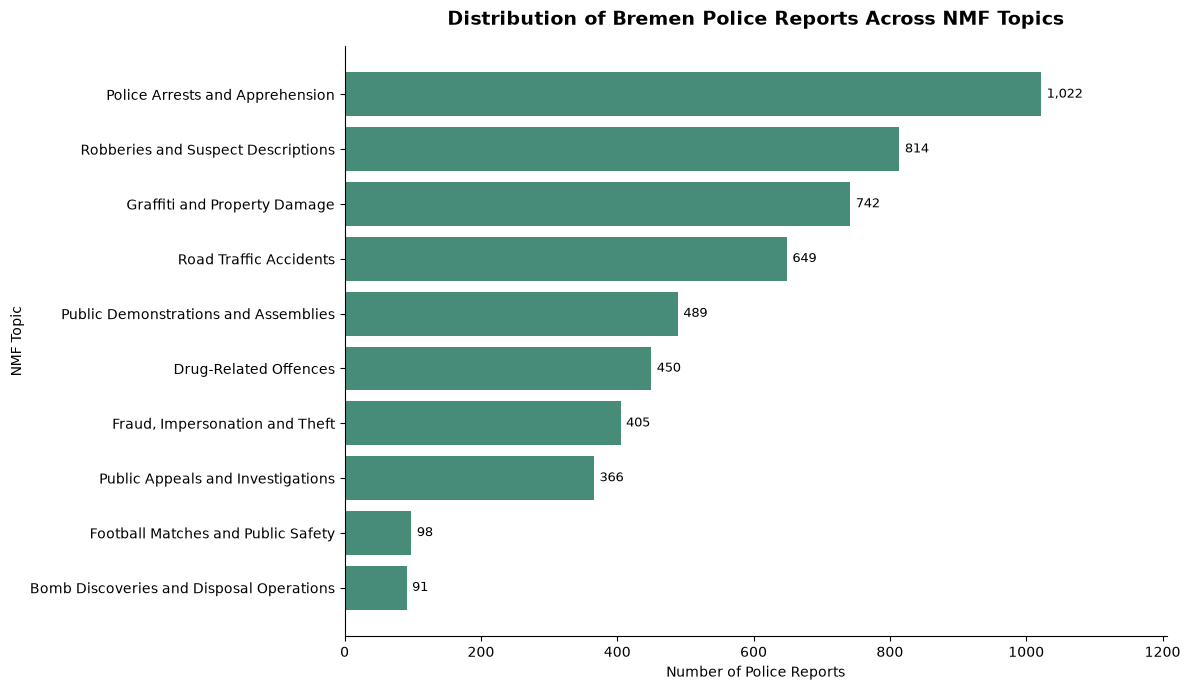

Chart saved to: C:\Users\ZIZIPHO\bremen-crime-data-analytics\figures\member_03\nmf_descriptions_topic_sizes.png
File exists: True


In [52]:

# Section 7: Create and save NMF topic-size chart

import matplotlib.pyplot as plt

# Create the correct figures folder
figure_dir = project_root / "figures" / "member_03"
figure_dir.mkdir(parents=True, exist_ok=True)

# Prepare topic counts
chart_data = topics_export.sort_values("n_reports")

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["proposed_category"],
    chart_data["n_reports"],
    color="#478C78"
)

# Add report counts at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Distribution of Bremen Police Reports Across NMF Topics",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Police Reports")
ax.set_ylabel("NMF Topic")

ax.set_xlim(0, chart_data["n_reports"].max() * 1.18)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save the chart
figure_path = figure_dir / "nmf_descriptions_topic_sizes.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", figure_path.resolve())
print("File exists:", figure_path.exists())


### Interpretation of NMF Topic Distribution

The chart shows how 5,126 Bremen police reports were distributed across the 10 topics identified by the NMF model. Police Arrests and Apprehension was the largest topic, containing 1,022 reports, followed by Robberies and Suspect Descriptions with 814 reports and Graffiti and Property Damage with 742 reports. The smallest topics were Football Matches and Public Safety (98 reports) and Bomb Discoveries and Disposal Operations (91 reports).

The unequal topic sizes suggest that some themes are more prominent in the dataset than others. However, the number of reports assigned to a topic does not necessarily represent the actual frequency of a specific crime. NMF groups reports according to recurring language patterns, and some assignments may be ambiguous or include multiple themes.

These results provide useful information for evaluating topic coverage and balance. Further manual validation and comparison with other models are needed to determine how accurately the topics represent the underlying police reports.

In [53]:

# Section 7: Final NMF handover verification

import pandas as pd

required_files = [
    "nmf_descriptions_assignments.csv",
    "nmf_descriptions_topics.csv",
    "nmf_descriptions_samples.csv",
    "nmf_descriptions_run.csv",
    "run_metadata.json",
    "handover.md"
]

print("FINAL HANDOVER FILE CHECK\n")

for filename in required_files:
    file_path = output_dir / filename
    print(f"{filename}: {'FOUND' if file_path.is_file() else 'MISSING'}")

# Verify the figure
figure_path = project_root / "figures" / "member_03" / "nmf_descriptions_topic_sizes.png"

print("\nTopic-size chart:",
      "FOUND" if figure_path.is_file() else "MISSING")

# Verify the four CSV files
assignments = pd.read_csv(
    output_dir / "nmf_descriptions_assignments.csv"
)

topics = pd.read_csv(
    output_dir / "nmf_descriptions_topics.csv"
)

samples = pd.read_csv(
    output_dir / "nmf_descriptions_samples.csv"
)

run = pd.read_csv(
    output_dir / "nmf_descriptions_run.csv"
)

print("\nDATA VERIFICATION")
print("Assignments:", len(assignments))
print("Unique report IDs:", assignments["report_id"].nunique())
print("Topics:", len(topics))
print("Review samples:", len(samples))
print("Run summary rows:", len(run))
print("Total topic counts:", topics["n_reports"].sum())

print("\nCONSISTENCY CHECKS")
print("All report IDs unique:",
      assignments["report_id"].is_unique)

print("All reports assigned:",
      assignments["assignment_status"].eq("assigned").all())

print("Topic counts match assignments:",
      topics["n_reports"].sum() == len(assignments))

print("All 10 topics represented:",
      set(assignments["topic_id"]) == set(topics["topic_id"]))

print("Five samples per topic:",
      samples.groupby("topic_id").size().eq(5).all())


FINAL HANDOVER FILE CHECK

nmf_descriptions_assignments.csv: FOUND
nmf_descriptions_topics.csv: FOUND
nmf_descriptions_samples.csv: FOUND
nmf_descriptions_run.csv: FOUND
run_metadata.json: FOUND
handover.md: FOUND

Topic-size chart: FOUND

DATA VERIFICATION
Assignments: 5126
Unique report IDs: 5126
Topics: 10
Review samples: 50
Run summary rows: 1
Total topic counts: 5126

CONSISTENCY CHECKS
All report IDs unique: True
All reports assigned: True
Topic counts match assignments: True
All 10 topics represented: True
Five samples per topic: True


In [54]:

# Section 7: Inspect the official artifact contract

import json

contract_path = project_root / "artifact_contracts.json"

with open(contract_path, "r", encoding="utf-8") as f:
    contract = json.load(f)

print("Artifact contract file:", contract_path.resolve())
print("\nContract structure:")
print(json.dumps(contract, indent=2, ensure_ascii=False)[:12000])


Artifact contract file: C:\Users\ZIZIPHO\bremen-crime-data-analytics\artifact_contracts.json

Contract structure:
{
  "project": "Bremen Police Reports Project 2: Data Analytics",
  "status": "SKELETON_NO_ANALYTICAL_RESULTS",
  "id_column": "report_id",
  "base_sha256": "e413c6bcca065480e00084bac8f18e338325803f3f79bf953b4b5f19c88c0534",
  "base_rows": 5126,
  "model_ids": [
    "nmf_titles",
    "nmf_descriptions",
    "bertopic_titles",
    "bertopic_descriptions"
  ],
  "assignment_status_values": [
    "assigned",
    "unassigned",
    "excluded",
    "missing_text",
    "invalid_embedding"
  ],
  "category_status_values": [
    "mapped_topic",
    "manual_override",
    "unclear",
    "unassigned",
    "excluded",
    "missing_text",
    "invalid_embedding"
  ],
  "elderly_status_values": [
    "yes",
    "no_evidence",
    "unclear",
    "not_reviewed",
    "excluded"
  ],
  "csv_rule": "UTF-8 CSV, index=False; preserve report_id strings; empty topic_id allowed for missing/exclude

In [55]:

# Section 7: Find artifact contract requirements

print("TOP-LEVEL CONTRACT SECTIONS\n")

for key, value in contract.items():
    print(f"{key}: {type(value).__name__}")

print("\nCSV FILE REQUIREMENTS\n")

def find_contract_sections(data, path="contract"):
    if isinstance(data, dict):
        for key, value in data.items():
            current_path = f"{path}.{key}"

            if any(word in key.lower() for word in [
                "assignment", "topic", "sample", "run", "schema"
            ]):
                if isinstance(value, (dict, list)):
                    print(f"\n{current_path}:")
                    print(str(value)[:1500])

            if isinstance(value, (dict, list)):
                find_contract_sections(value, current_path)

    elif isinstance(data, list):
        for index, value in enumerate(data):
            if isinstance(value, (dict, list)):
                find_contract_sections(
                    value, f"{path}[{index}]"
                )

find_contract_sections(contract)


TOP-LEVEL CONTRACT SECTIONS

project: str
status: str
id_column: str
base_sha256: str
base_rows: int
model_ids: list
assignment_status_values: list
category_status_values: list
elderly_status_values: list
csv_rule: str
parquet_rule: str
model_row_rule: str
model_topic_rule: str
prepared_checksum_rule: str
review_rule: str
mapping_rule: str
overrides_rule: str
district_share_definitions: dict
roles: dict

CSV FILE REQUIREMENTS


contract.assignment_status_values:
['assigned', 'unassigned', 'excluded', 'missing_text', 'invalid_embedding']

contract.roles.member_01.csv_schemas:
{'data_quality.csv': ['check', 'value', 'notes'], 'district_lookup.csv': ['district_original', 'district_clean', 'decision', 'notes'], 'duplicate_review.csv': ['report_id', 'url', 'decision', 'reason'], 'district_category_counts.csv': ['district_clean', 'crime_category', 'report_count', 'share_within_district', 'share_of_category_reports'], 'highest_district_by_category.csv': ['crime_category', 'district_clean', 'r

In [56]:

# Section 7: Inspect Member 3's artifact requirements only

member_03_contract = contract["roles"]["member_03"]

print("MEMBER 3 CONTRACT REQUIREMENTS\n")

import json

print(json.dumps(
    member_03_contract,
    indent=2,
    ensure_ascii=False
))


MEMBER 3 CONTRACT REQUIREMENTS

{
  "notebook": "team_notebooks/03_description_topic_modeling.ipynb",
  "title": "Topic modeling using descriptions",
  "output_folder": "outputs/member_03",
  "required_files": [
    "nmf_descriptions_assignments.csv",
    "nmf_descriptions_topics.csv",
    "nmf_descriptions_samples.csv",
    "nmf_descriptions_run.csv",
    "run_metadata.json",
    "handover.md"
  ],
  "csv_schemas": {
    "nmf_descriptions_assignments.csv": [
      "report_id",
      "model_id",
      "topic_id",
      "assignment_status"
    ],
    "nmf_descriptions_topics.csv": [
      "model_id",
      "topic_id",
      "keywords",
      "n_reports",
      "proposed_category",
      "notes"
    ],
    "nmf_descriptions_samples.csv": [
      "model_id",
      "topic_id",
      "report_id",
      "selection_reason"
    ],
    "nmf_descriptions_run.csv": [
      "model_id",
      "n_topics",
      "assigned_reports",
      "unassigned_reports",
      "excluded_reports",
      "missing_

In [57]:

# Section 7: Automatically validate Member 3 CSV schemas

import pandas as pd

expected_schemas = member_03_contract["csv_schemas"]

print("MEMBER 3 CSV CONTRACT VALIDATION\n")

all_passed = True

for filename, expected_columns in expected_schemas.items():

    file_path = output_dir / filename

    if not file_path.exists():
        print(f"{filename}: FAIL - file missing")
        all_passed = False
        continue

    actual_columns = pd.read_csv(
        file_path,
        nrows=0
    ).columns.tolist()

    matches = actual_columns == expected_columns

    print(f"{filename}: {'PASS' if matches else 'FAIL'}")

    if not matches:
        all_passed = False
        print("  Expected:", expected_columns)
        print("  Actual:  ", actual_columns)

print("\nOVERALL RESULT:")
print("ALL CSV SCHEMAS PASS" if all_passed
      else "SOME CSV SCHEMAS NEED CORRECTION")


MEMBER 3 CSV CONTRACT VALIDATION

nmf_descriptions_assignments.csv: PASS
nmf_descriptions_topics.csv: PASS
nmf_descriptions_samples.csv: PASS
nmf_descriptions_run.csv: PASS

OVERALL RESULT:
ALL CSV SCHEMAS PASS


**Things to note for this field:** Descriptions give fuller context but may contain repetitive reporting language, several offenses and witness/suspect details. More text does not automatically mean a better crime category.

## What you must submit to the main workstation

Submit this completed notebook with saved outputs, your files in outputs/member_03, and figures in figures/member_03. Run the notebook top-to-bottom before submission. Do not submit empty templates as results.

- **nmf_descriptions_assignments.csv** = columns: `report_id`, `model_id`, `topic_id`, `assignment_status`.
- **nmf_descriptions_topics.csv** = columns: `model_id`, `topic_id`, `keywords`, `n_reports`, `proposed_category`, `notes`.
- **nmf_descriptions_samples.csv** = columns: `model_id`, `topic_id`, `report_id`, `selection_reason`.
- **nmf_descriptions_run.csv** = columns: `model_id`, `n_topics`, `assigned_reports`, `unassigned_reports`, `excluded_reports`, `missing_text_reports`, `invalid_embedding_reports`, `elapsed_seconds`, `parameters`.
- **run_metadata.json** = name, input checksums, package versions, method settings, run date, record counts and status.
- **handover.md** = what you did, results, limitations, reviewer comments, output inventory and outstanding questions.

**Main notebook destination:** Topic modeling: descriptions; Model comparison and approved labels.

Member 6 needs assignments, topic descriptions and example IDs. Use the shared output schemas, not a custom column naming scheme. Share model mistakes with the group as well as successful examples.
### Output conventions

- Keep report_id as the original BR string. Topic IDs are integers within a model, or empty for missing/excluded inputs; HDBSCAN noise is -1.
- For model tables, use the exact model_id and assignment_status values: assigned, unassigned, excluded, missing_text, invalid_embedding. Keywords can be semicolon-separated text. n_reports is the number of reports represented by that topic/status, not a score.
- Store shares/agreement rates as fractions from 0 to 1; multiply by 100 only when displaying percentages. Record which report set is the denominator. A model weight is not a calibrated category probability.
- Date keys use YYYY-MM-DD; monthly keys use YYYY-MM. Keep literal text labels intact when reading lookup CSVs (keep_default_na=False can preserve the original text None).
- Copy templates/member_XX/run_metadata.json into your output folder only when filling it with an actual run. Keep the common metadata keys, replace placeholders, and mark submitted/reviewed only when true. Record SHA-256 file versions, not just filenames.
- Final category statuses are mapped_topic/manual_override/unclear/unassigned/excluded/missing_text/invalid_embedding. Elderly review statuses are yes/no_evidence/unclear/not_reviewed/excluded. Unclear and unreviewed are not negative results.

### Final submission checks

- [ ] All expected output files are populated, or a genuine empty result is explained (for example, no anomalies met the rule).
- [ ] Every report-level table uses report_id and includes the required cohort, without unexpected duplicates.
- [ ] IDs, source/prepared checksums, categories and denominators match the shared contract.
- [ ] Required charts have descriptive titles, labels, units, periods and readable text; export PNG/HTML as appropriate.
- [ ] Code runs in order; results and explanations agree; raw/debug output is bounded.
- [ ] A peer reviewer has checked the method, sample reports, files and conclusions.
- [ ] handover.md says exactly what to import into the main notebook and lists anything still unresolved.

### Your handover summary

**What I completed:** ______  
**Most useful finding (after execution):** ______  
**Output files and row counts:** ______  
**Main limitations:** ______  
**Reviewer decision:** ______  
**Next person who needs my outputs:** ______


In [58]:
print("My notebook is working!")

My notebook is working!
